# Analyse Exploratoire des Données (EDA) — Titanic & Préparation pour un SVM

Bienvenue dans ce guide pas-à-pas dédié à l'**Analyse Exploratoire des Données** (*Exploratory Data Analysis* ou **EDA**) du célèbre jeu de données **Titanic**.


## Pourquoi faire une EDA avant de nettoyer les données ?

En Data Science et en Machine Learning, une erreur fréquente chez les étudiants/débutants est de vouloir nettoyer ou transformer les données immédiatement, à l'aveugle. **L'EDA est l'étape d'observation médicale avant l'opération chirurgicale** :

1. **Règle d'or de l'EDA** : **On ne modifie jamais et on ne découpe pas le jeu de données d'origine pendant l'exploration.** On observe l'intégralité du fichier (`1 309 passagers`), on mesure, on trace des graphiques et on établit un diagnostic.

2. **Comprendre le métier et l'histoire** : Derrière chaque ligne se trouve un passager du RMS Titanic (naufrage du 15 avril 1912). Les règles sociales de l'époque (*« les femmes et les enfants d'abord »*, la proximité des cabines de 1ère classe avec les canots) expliquent la structure mathématique des données.

3. **Préparer spécifiquement le modèle SVM (*Support Vector Machine*)** :

   - Contrairement aux arbres de décision, un **SVM est un modèle géométrique** qui cherche à tracer une frontière (un *hyperplan*) ayant la plus grande marge possible entre les survivants (`1`) et les victimes (`0`).

   - Il calcule des **distances mathématiques** entre les passagers dans l'espace des variables.

   - Par conséquent, un SVM :
     - **Ne tolère aucune valeur manquante (`NaN`)** ;
     - **Ne comprend que les nombres** (il faudra encoder le texte et les catégories) ;
     - **Est extrêmement sensible aux différences d'échelle et aux valeurs extrêmes (*outliers*)** : si une variable varie de `0` à `512` (le prix du billet `Fare`) et une autre de `0` à `1` (le sexe `Sex`), le SVM ne verra que le prix du billet !



## Sommaire de notre exploration

1. **Chargement et vue d'ensemble** (dimensions, types de variables, aperçu)
2. **Contrôle d'intégrité** (recherche de doublons et vérification des homonymes)
3. **Audit des valeurs manquantes (`NaN`)** et stratégies d'imputation
4. **Détection du *Data Leakage* (Fuite de données)** 
5. **Analyse de la variable cible (`Survived`)** : équilibre des classes
6. **Analyse des variables catégorielles**
7. **Analyse des variables numériques, asymétrie (*Skewness*) et *Outliers*** 
8. **Analyse des variables textuelles et à haute cardinalité** 
9. **Analyse multivariée et corrélations** (interactions entre variables)
10. **Bilan de l'EDA : Feuille de route du nettoyage et du découpage (`train_test_split`) pour le SVM**


In [4]:
# Importation des bibliothèques fondamentales de Data Science
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique des graphiques pour une lecture claire
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Chargement du dataset en lecture seule (aucune modification du fichier CSV)
df = pd.read_csv("dataset/titanic.csv")

print(f"Dataset chargé avec succès : {df.shape[0]} passagers (lignes) et {df.shape[1]} variables (colonnes).")


Dataset chargé avec succès : 1309 passagers (lignes) et 15 variables (colonnes).


## 1. Vue d'ensemble et types de données

En Machine Learning, on distingue deux grands types de colonnes dans un tableau :

- **La variable cible (*Target*, notée $y$)** : C'est ce que l'on cherche à prédire. Ici, c'est `Survived` (`1` = a survécu, `0` = est décédé).

- **Les variables explicatives (*Features*, notées $X$)** : Ce sont les indices (âge, sexe, classe, prix du billet...) que le SVM utilisera pour prendre sa décision.

Sous Python (`pandas`), les colonnes ont principalement trois types informatiques :

- `int64` : Nombres entiers. 

    *Attention : un nombre entier comme `Pclass` (1, 2, 3) représente en réalité une catégorie ordonnée !*

- `float64` : Nombres décimaux. Notons que `pandas` utilise aussi `float64` dès qu'une colonne d'entiers contient des valeurs manquantes (`NaN`).

- `object` : Texte ou chaînes de caractères (ex: nom, pays, sexe).


In [5]:
# Aperçu des 5 premiers passagers
display(df.head())

# Informations techniques sur les types et les valeurs non-nulles
print("\nStructure technique du DataFrame\n")
df.info()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,boat,body,home.dest
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,NaN,NaN,"Bridgerule, Devon"
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,4,NaN,"New York, NY"
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,NaN,NaN,NaN
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,D,NaN,"Scituate, MA"
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,NaN,NaN,"Lower Clapton, Middlesex or Erdington, Birmingham"



Structure technique du DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  1309 non-null   int64  
 1   Survived     1309 non-null   int64  
 2   Pclass       1309 non-null   int64  
 3   Name         1309 non-null   object 
 4   Sex          1309 non-null   object 
 5   Age          1046 non-null   float64
 6   SibSp        1309 non-null   int64  
 7   Parch        1309 non-null   int64  
 8   Ticket       1309 non-null   object 
 9   Fare         1308 non-null   float64
 10  Cabin        295 non-null    object 
 11  Embarked     1307 non-null   object 
 12  boat         486 non-null    object 
 13  body         121 non-null    float64
 14  home.dest    745 non-null    object 
dtypes: float64(3), int64(5), object(7)
memory usage: 153.5+ KB


## 2. Contrôle d'intégrité : Doublons et Homonymes

Avant d'analyser les distributions statistiques, on vérifie toujours qu'il n'y a pas d'erreurs de saisie manifestes comme :
1. **Des lignes strictement dupliquées** (un même passager copié deux fois par erreur dans le fichier).

2. **Des doublons sur le nom (`Name`)** : s'agit-il d'une erreur informatique ou de vrais homonymes (deux personnes différentes portant le même nom et prénom) ?


In [6]:
# 1. Vérification des lignes entièrement dupliquées
nb_doublons = df.duplicated().sum()
print(f"Nombre de lignes strictement identiques (doublons) : {nb_doublons}")

# 2. Vérification des homonymes sur la colonne Name
homonymes = df[df.duplicated(subset=["Name"], keep=False)].sort_values("Name")
print(f"Nombre de passagers partageant exactement le même nom : {len(homonymes)}")
display(homonymes[["PassengerId", "Survived", "Pclass", "Name", "Age", "Ticket", "Embarked"]])


Nombre de lignes strictement identiques (doublons) : 0
Nombre de passagers partageant exactement le même nom : 4


,PassengerId,Survived,Pclass,Name,Age,Ticket,Embarked
289,290,1,3,"Connolly, Miss. Kate",22.0,370373,Q
897,898,0,3,"Connolly, Miss. Kate",30.0,330972,Q
696,697,0,3,"Kelly, Mr. James",44.0,363592,S
891,892,0,3,"Kelly, Mr. James",34.5,330911,Q


**Observations :**

- **Aucune ligne dupliquée (`0`)**.

- **Les 4 passagers ayant un nom en double sont de vrais homonymes historiques** : les deux `"Connolly, Miss. Kate"` (22 ans et 30 ans) et les deux `"Kelly, Mr. James"` (34,5 ans et 44 ans) ont des âges, des numéros de billets (`Ticket`) et parfois des ports d'embarquement différents. Il ne faut donc supprimer aucune ligne !


## 3. Audit des valeurs manquantes (`NaN`)

En Python, une case vide est représentée par `NaN` (*Not a Number*).
Or, **un algorithme SVM plante immédiatement s'il rencontre un seul `NaN`**, car il est impossible de calculer une distance géométrique avec une valeur inconnue.

Observons quelles colonnes sont touchées et dans quelles proportions sur nos 1 309 passagers :


,Valeurs Présentes,Valeurs Manquantes (NaN),Pourcentage Manquant (%)
body,121,1188,90.76
Cabin,295,1014,77.46
boat,486,823,62.87
home.dest,745,564,43.09
Age,1046,263,20.09
Embarked,1307,2,0.15
Fare,1308,1,0.08


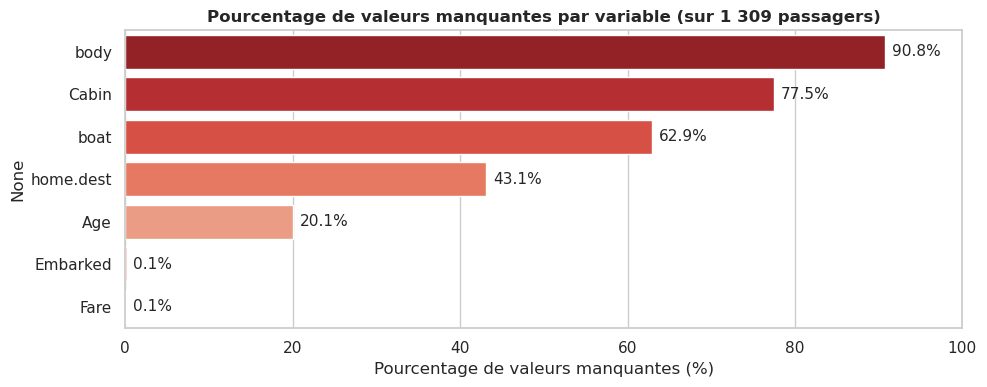

In [7]:
# Calcul du nombre et du pourcentage de valeurs manquantes par colonne
manquants = pd.DataFrame({
    "Valeurs Présentes": df.notnull().sum(),
    "Valeurs Manquantes (NaN)": df.isnull().sum(),
    "Pourcentage Manquant (%)": (df.isnull().mean() * 100).round(2)
}).sort_values(by="Pourcentage Manquant (%)", ascending=False)

display(manquants[manquants["Valeurs Manquantes (NaN)"] > 0])

# Visualisation graphique des valeurs manquantes
fig, ax = plt.subplots(figsize=(10, 4))
cols_na = manquants[manquants["Valeurs Manquantes (NaN)"] > 0]
sns.barplot(
    x=cols_na["Pourcentage Manquant (%)"],
    y=cols_na.index,
    hue=cols_na.index,
    palette="Reds_r",
    legend=False,
    ax=ax
)
ax.set_title("Pourcentage de valeurs manquantes par variable (sur 1 309 passagers)", fontweight="bold")
ax.set_xlabel("Pourcentage de valeurs manquantes (%)")
ax.set_xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=5)

plt.tight_layout()
plt.show()


In [5]:
# Regardons de près les 3 passagers à qui il manque juste 'Fare' (1 seul) ou 'Embarked' (2 seulement)
print("Passagers ayant 'Fare' ou 'Embarked' manquant :")
display(df[df["Fare"].isnull() | df["Embarked"].isnull()][
    ["PassengerId", "Survived", "Pclass", "Name", "Sex", "Age", "Ticket", "Fare", "Cabin", "Embarked"]
])


Passagers ayant 'Fare' ou 'Embarked' manquant :


,PassengerId,Survived,Pclass,Name,Sex,Age,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,113572,80.0,B28,NaN
1043,1044,0,3,"Storey, Mr. Thomas",male,60.5,3701,NaN,NaN,S


### Que nous apprend cet audit des valeurs manquantes ?

On distingue 4 catégories très différentes de valeurs manquantes :
1. **Les colonnes de fuite de données (`body` : 90,8 %, `boat` : 62,9 %)** : Elles doivent être supprimées (voir section suivante).

2. **Les colonnes trop vides ou textuelles bruitées (`Cabin` : 77,5 % manquant, `home.dest` : 43,1 % manquant)** :

   - Plus des trois quarts des passagers n'ont pas de numéro de cabine renseigné (surtout en 3ème classe). Remplacer 77,5 % d'une colonne par une valeur inventée introduirait un bruit énorme dans le SVM. Dans un pipeline de nettoyage standard, on supprime `Cabin` et `home.dest`.

3. **La variable `Age` (20,1 % manquant, soit 263 passagers)** :

   - L'âge est crucial (*« les femmes et les enfants d'abord »*), on ne peut pas supprimer la colonne !

   - On ne peut pas non plus supprimer les 263 lignes (on perdrait 20 % du dataset).

   - **Solution pour le nettoyage** : **L'imputation** (remplacer les `NaN` par la **médiane** des âges observés grâce à `SimpleImputer(strategy='median')`).

4. **Les valeurs manquantes isolées (`Embarked` : 2 manquants, `Fare` : 1 manquant)** :

   - `Embarked` n'a que 2 valeurs manquantes (Miss Amelie Icard et Mrs George Nelson Stone, qui voyageaient ensemble en 1ère classe). On les remplacera simplement par le port le plus fréquent (**la valeur modale `most_frequent`**, soit Southampton `'S'`).
   
   - `Fare` n'a qu'une seule valeur manquante (Mr Thomas Storey, 60 ans, 3ème classe). On la remplacera par la **médiane** des prix avec `SimpleImputer(strategy='median')`.


## 4. Détection du *Data Leakage* (Fuite de données) : `boat` et `body`

> **Concept fondamental en Machine Learning : Le *Data Leakage* (Fuite d'information du futur)**
> 
> Le *Data Leakage* survient lorsqu'on laisse dans les variables explicatives ($X$) une information qui **n'existait pas au moment où l'on veut faire la prédiction** (ici, au moment où le Titanic quitte le port), mais qui a été enregistrée **après l'événement** et qui révèle directement la réponse ($y$).

Dans notre dataset `titanic.csv`, deux colonnes historiques accompagnent les caractéristiques des passagers :
- **`boat`** : Le numéro ou la lettre du canot de sauvetage dans lequel le passager a été secouru.
- **`body`** : Le numéro d'identification attribué au corps repêché en mer après le naufrage.

Vérifions mathématiquement ce qui se passe si on croise ces deux colonnes avec `Survived` :


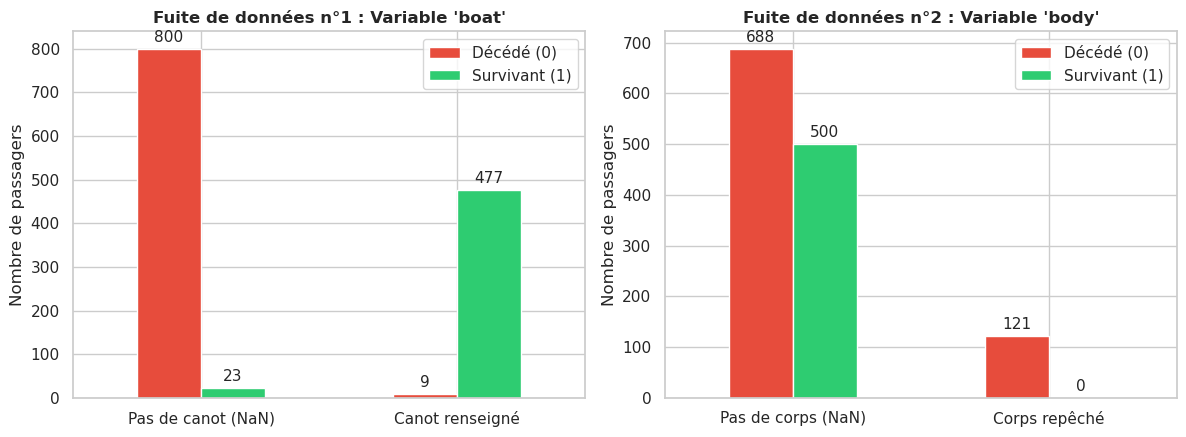

In [8]:
# Création temporaire (sans modifier df) d'indicateurs de présence de 'boat' et 'body'
a_un_canot = df["boat"].notnull()
corps_repeche = df["body"].notnull()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Graphique 1 : Présence d'un numéro de canot (boat) vs Survie
ct_boat = pd.crosstab(a_un_canot, df["Survived"])
ct_boat.index = ["Pas de canot (NaN)", "Canot renseigné"]
ct_boat.columns = ["Décédé (0)", "Survivant (1)"]
ct_boat.plot(kind="bar", stacked=False, color=["#e74c3c", "#2ecc71"], ax=axes[0], rot=0)
axes[0].set_title("Fuite de données n°1 : Variable 'boat'", fontweight="bold")
axes[0].set_ylabel("Nombre de passagers")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Graphique 2 : Présence d'un numéro de corps (body) vs Survie
ct_body = pd.crosstab(corps_repeche, df["Survived"])
ct_body.index = ["Pas de corps (NaN)", "Corps repêché"]
ct_body.columns = ["Décédé (0)", "Survivant (1)"]
ct_body.plot(kind="bar", stacked=False, color=["#e74c3c", "#2ecc71"], ax=axes[1], rot=0)
axes[1].set_title("Fuite de données n°2 : Variable 'body'", fontweight="bold")
axes[1].set_ylabel("Nombre de passagers")
for container in axes[1].containers:
    axes[1].bar_label(container, padding=3)

plt.tight_layout()
plt.show()


**Pourquoi faut-il absolument supprimer `boat` et `body` ?**

- Sur les **486 passagers** ayant un canot (`boat`) renseigné, **477 ont survécu (98,1 %)** (les 9 autres sont décédés d'hypothermie à bord des canots).
- Sur les **121 passagers** ayant un numéro de corps (`body`), **121 sont décédés (100 %)**.
- Si vous donnez `boat` et `body` à notre SVM, il obtiendra ~98 % de réussite sans rien apprendre des caractéristiques des passagers : il triche en regardant le rapport des secours après le naufrage ! **Ces deux colonnes doivent donc impérativement être supprimées dès la première étape du nettoyage.**


## 5. Analyse de la variable cible : `Survived`

Quand on prépare un classifieur binaire comme un SVM, il faut toujours regarder l'**équilibre des classes** (*Class Balance*) :
- Si une classe représente 99 % des données et l'autre 1 %, le modèle peut prédire tout le temps la classe majoritaire et avoir 99 % de précision (*accuracy*) tout en étant inutile.
- Voyons quelle est la répartition exacte entre victimes (`0`) et survivants (`1`) sur les 1 309 passagers :


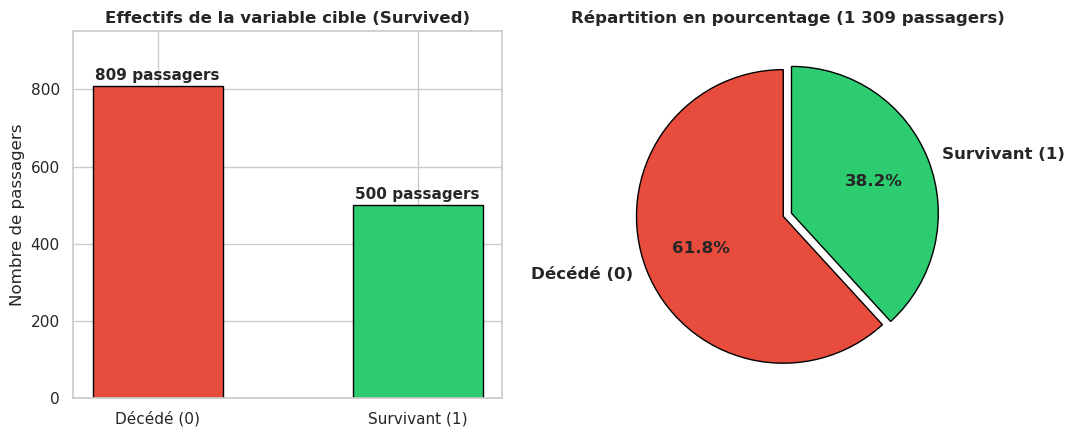

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Comptage global
counts = df["Survived"].value_counts()
labels = ["Décédé (0)", "Survivant (1)"]
colors = ["#e74c3c", "#2ecc71"]

# Graphique 1 : Effectifs en barres
axes[0].bar(labels, counts.values, color=colors, width=0.5, edgecolor="black")
axes[0].set_title("Effectifs de la variable cible (Survived)", fontweight="bold")
axes[0].set_ylabel("Nombre de passagers")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 15, f"{v} passagers", ha="center", fontweight="bold")
axes[0].set_ylim(0, 950)

# Graphique 2 : Proportions en camembert (Pie chart)
axes[1].pie(
    counts.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=(0.03, 0.03),
    textprops={"fontweight": "bold", "fontsize": 12},
    wedgeprops={"edgecolor": "black", "linewidth": 1}
)
axes[1].set_title("Répartition en pourcentage (1 309 passagers)", fontweight="bold")

plt.tight_layout()
plt.show()


**Conclusion sur la cible `Survived` :**

- **61,8% de décédés (809 passagers)** contre **38,2% de survivants (500 passagers)**.
- Le jeu de données présente un **léger déséquilibre (~62% / 38%)**, fidèle au bilan historique de la tragédie, mais on peut dire qu'il n'est pas considéré comme sévèrement déséquilibré.
- **Conséquence pour notre future découpe Train / Test** : Lorsqu'on utilisera `train_test_split`, nous ajouterons l'option **`stratify=y`** pour garantir que le jeu d'entraînement (`Train`) et le jeu de test (`Test`) conserveront exactement cette proportion de **61,8 % / 38,2%**.
- **Indicateur de référence (*Baseline*)** : Un modèle naïf qui prédirait que **tout le monde meurt (`0`)** aurait déjà raison dans **61,8%** des cas ! Notre SVM devra donc faire nettement mieux que 61,8 % d'*accuracy* (idéalement autour de **80 % à 83 %**).


## 6. Analyse des variables catégorielles : `Sex`, `Pclass`, `Embarked`

Les variables catégorielles classent les passagers dans un nombre restreint de groupes :
1. **`Sex`** (*Catégorielle binaire*) : `'male'` (homme) ou `'female'` (femme).
2. **`Pclass`** (*Catégorielle ordinale*) : `1` (1ère classe - ponts supérieurs), `2` (2ème classe), `3` (3ème classe - ponts inférieurs).
3. **`Embarked`** (*Catégorielle nominale*) : Port d'embarquement (`'S'` = Southampton en Angleterre, `'C'` = Cherbourg en France, `'Q'` = Queenstown en Irlande).

Regardons comment chacune de ces trois variables influence la probabilité de survie :


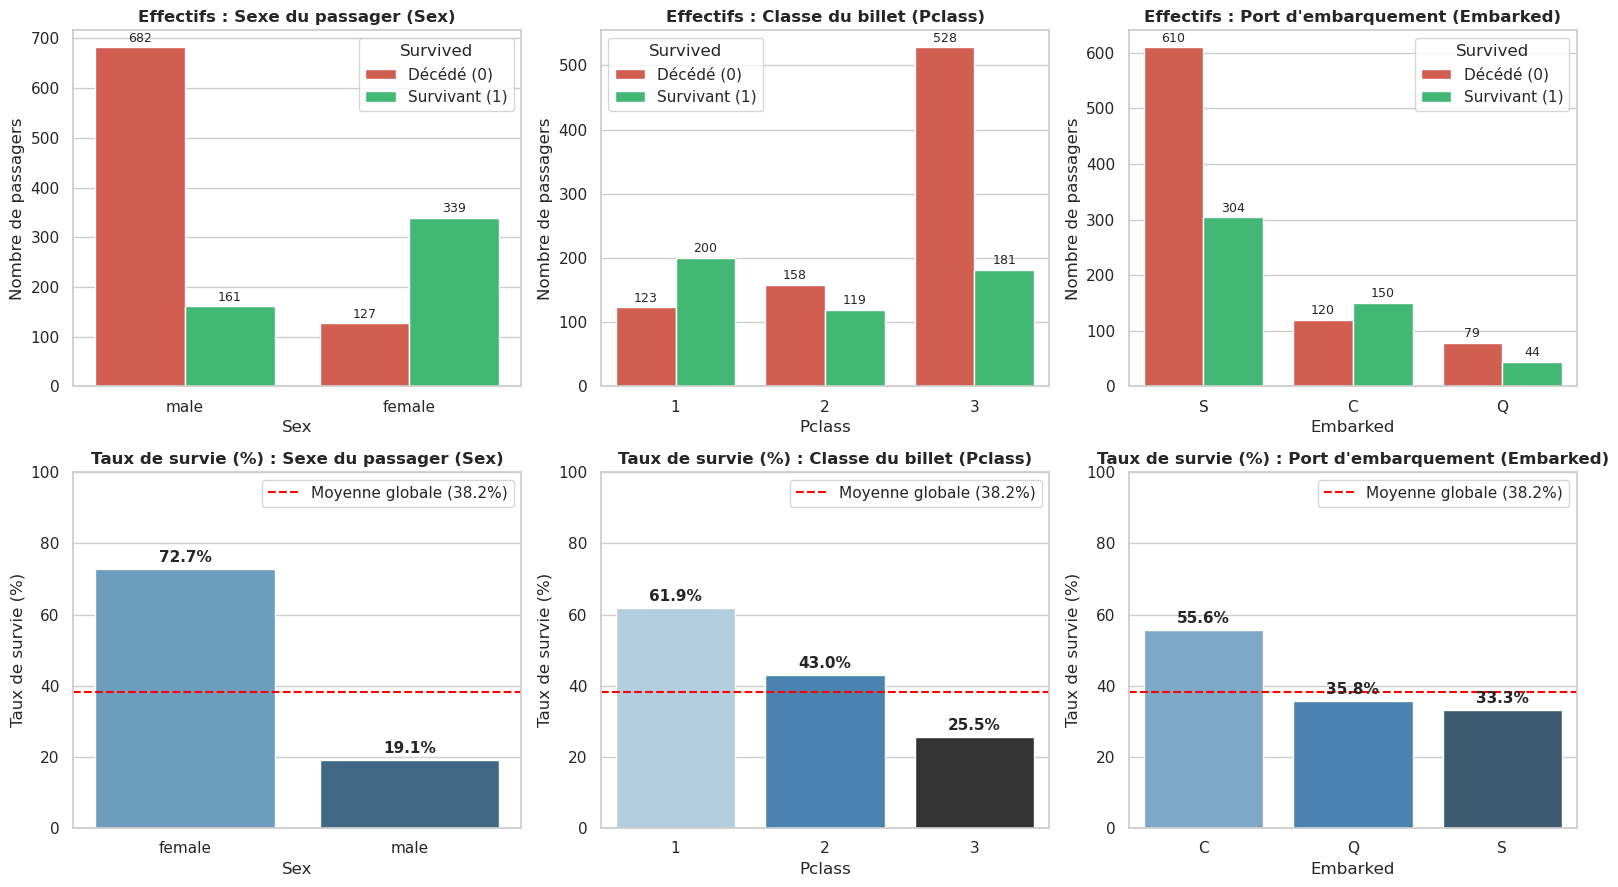

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

cat_cols = [
    ("Sex", "Sexe du passager (Sex)"),
    ("Pclass", "Classe du billet (Pclass)"),
    ("Embarked", "Port d'embarquement (Embarked)")
]

for idx, (col, title) in enumerate(cat_cols):
    # Ligne 1 : Effectifs par catégorie selon Survived
    sns.countplot(data=df, x=col, hue="Survived", palette=["#e74c3c", "#2ecc71"], ax=axes[0, idx])
    axes[0, idx].set_title(f"Effectifs : {title}", fontweight="bold")
    axes[0, idx].set_ylabel("Nombre de passagers")
    axes[0, idx].legend(title="Survived", labels=["Décédé (0)", "Survivant (1)"])
    for container in axes[0, idx].containers:
        axes[0, idx].bar_label(container, padding=2, fontsize=9)

    # Ligne 2 : Taux de survie moyen (%)
    surv_rate = df.groupby(col)["Survived"].mean() * 100
    sns.barplot(x=surv_rate.index, y=surv_rate.values, hue=surv_rate.index, palette="Blues_d", legend=False, ax=axes[1, idx])
    axes[1, idx].axhline(df["Survived"].mean() * 100, color="red", linestyle="--", label="Moyenne globale (38.2%)")
    axes[1, idx].set_title(f"Taux de survie (%) : {title}", fontweight="bold")
    axes[1, idx].set_ylabel("Taux de survie (%)")
    axes[1, idx].set_ylim(0, 100)
    axes[1, idx].legend()
    for container in axes[1, idx].containers:
        axes[1, idx].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold")

plt.tight_layout()
plt.show()


In [11]:
# Pourquoi les passagers embarqués à Cherbourg (C) survivent-ils beaucoup plus (55.6%) que ceux de Southampton (33.3%) ?
# Regardons la répartition des classes sociales (Pclass) selon le port d'embarquement !
ct_emb_pclass = pd.crosstab(df["Embarked"], df["Pclass"], normalize="index") * 100
ct_emb_pclass.columns = ["1ère Classe (%)", "2ème Classe (%)", "3ème Classe (%)"]
display(ct_emb_pclass.round(1))


,1ère Classe (%),2ème Classe (%),3ème Classe (%)
Embarked,,,
C,52.2,10.4,37.4
Q,2.4,5.7,91.9
S,19.4,26.5,54.2


### Analyse et impact direct sur la préparation pour le SVM

1. **`Sex` est la variable la plus prédictive du jeu de données** :
   - **72,7 % des femmes** ont survécu, contre seulement **19,1 % des hommes** ! La consigne *« les femmes et les enfants d'abord »* a été appliquée très strictement.
   - **Comment l'encoder pour le SVM ?** Comme il n'y a que 2 modalités (`male` / `female`), on utilise un **encodage binaire (`OrdinalEncoder`)** qui transforme `'male' en 0` et `'female' en 1` sur une seule colonne.

2. **`Pclass` reflète l'accès aux canots de sauvetage** :
   - Taux de survie : **61,9 % en 1ère classe**, **43,0 % en 2ème classe**, et seulement **25,5 % en 3ème classe** (qui représentait pourtant plus de la moitié du navire : 709 passagers).

3. **`Embarked` est indirectement corrélé à la classe sociale** :
   - Les passagers montés à **Cherbourg (`C`)** ont survécu à **55,6 %** parce que **52,2 % d'entre eux voyageaient en 1ère classe** ! À l'inverse, **91,9 %** des passagers montés à **Queenstown (`Q`)** étaient des émigrants irlandais de 3ème classe.

4. **Comment encoder `Embarked` et `Pclass` pour un SVM ? (`OneHotEncoder`)** :
   - Pour `Embarked` (`C`, `Q`, `S`), il n'y a aucun ordre naturel. Si on codait `C=1, Q=2, S=3`, le SVM croirait mathématiquement que Queenstown (`2`) est la moyenne entre Cherbourg (`1`) et Southampton (`3`), et que Southampton est "3 fois plus grand" que Cherbourg.
   - On va donc utiliser le **`OneHotEncoder(drop='first')`** : il crée des colonnes binaires (`0` ou `1`) indépendantes pour chaque catégorie (en omettant la première catégorie de référence pour éviter la redondance mathématique appelée *colinéarité*). Appliquer aussi le `OneHotEncoder` à `Pclass` permet au SVM d'attribuer un poids libre et non-linéaire à chaque classe sociale.


## 7. Analyse des variables numériques : `Age`, `Fare`, `SibSp`, `Parch`

Un algorithme **SVM est extrêmement sensible à la forme géométrique des variables numériques** :
1. **La différence d'échelle** : Si `Fare` va de `0` à `512` et `SibSp` de `0` à `8`, la distance euclidienne $\|\mathbf{x}_i - \mathbf{x}_j\|^2$ calculée par le noyau du SVM (notamment le noyau RBF ou linéaire) sera écrasée à 99 % par `Fare`. **La standardisation (`StandardScaler` : moyenne = 0, écart-type = 1) est donc obligatoire.**

2. **L'asymétrie (*Skewness*) et les valeurs extrêmes (*Outliers*)** : Si une variable possède une très longue queue de distribution vers la droite (quelques milliardaires ayant payé 512 £ alors que le billet médian coûte 14,45 £), la moyenne et l'écart-type sont déformés.

Examinons les statistiques descriptives et les distributions de nos 4 variables numériques :


In [12]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]

# Tableau statistique enrichi avec la médiane, l'écart interquartile (IQR) et le coefficient d'asymétrie (Skewness)
stats_num = df[num_cols].describe().T
stats_num["median"] = df[num_cols].median()
stats_num["IQR"] = stats_num["75%"] - stats_num["25%"]
stats_num["skewness (asymétrie)"] = df[num_cols].skew()

display(stats_num[["count", "mean", "std", "min", "25%", "median", "75%", "max", "IQR", "skewness (asymétrie)"]].round(2))


,count,mean,std,min,25%,median,75%,max,IQR,skewness (asymétrie)
Age,1046.0,29.88,14.41,0.17,21.0,28.00,39.00,80.00,18.00,0.41
Fare,1308.0,33.30,51.76,0.00,7.9,14.45,31.28,512.33,23.38,4.37
SibSp,1309.0,0.50,1.04,0.00,0.0,0.00,1.00,8.00,1.00,3.84
Parch,1309.0,0.39,0.87,0.00,0.0,0.00,0.00,9.00,0.00,3.67


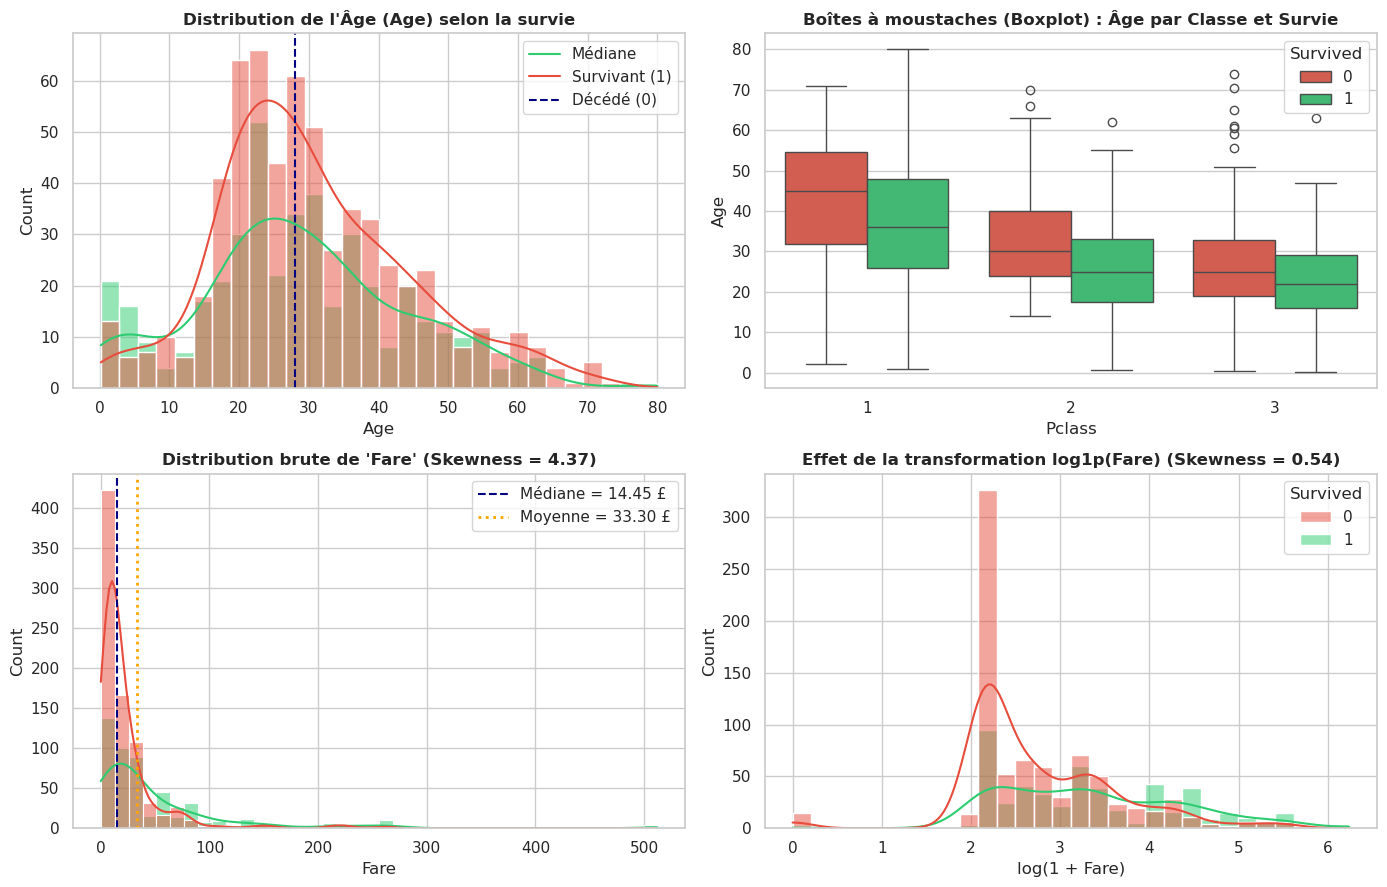

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1- Distribution de l'âge selon la survie
sns.histplot(data=df, x="Age", hue="Survived", kde=True, bins=30, palette=["#e74c3c", "#2ecc71"], ax=axes[0, 0])
axes[0, 0].axvline(df["Age"].median(), color="navy", linestyle="--", label=f"Médiane = {df['Age'].median():.0f} ans")
axes[0, 0].set_title("Distribution de l'Âge (Age) selon la survie", fontweight="bold")
axes[0, 0].legend(labels=["Médiane", "Survivant (1)", "Décédé (0)"])

# 2 Boxplot de l'âge par classe sociale (Pclass)
sns.boxplot(data=df, x="Pclass", y="Age", hue="Survived", palette=["#e74c3c", "#2ecc71"], ax=axes[0, 1])
axes[0, 1].set_title("Boîtes à moustaches (Boxplot) : Âge par Classe et Survie", fontweight="bold")

# 3- Distribution brute de Fare (très asymétrique !)
sns.histplot(data=df, x="Fare", hue="Survived", kde=True, bins=40, palette=["#e74c3c", "#2ecc71"], ax=axes[1, 0])
axes[1, 0].axvline(df["Fare"].median(), color="navy", linestyle="--", label=f"Médiane = {df['Fare'].median():.2f} £")
axes[1, 0].axvline(df["Fare"].mean(), color="orange", linestyle=":", lw=2, label=f"Moyenne = {df['Fare'].mean():.2f} £")
axes[1, 0].set_title(f"Distribution brute de 'Fare' (Skewness = {df['Fare'].skew():.2f})", fontweight="bold")
axes[1, 0].legend()

# 4- Simulation visuelle de log1p(Fare) (sans modifier df !)
fare_log_sim = np.log1p(df["Fare"].dropna())
sns.histplot(x=fare_log_sim, hue=df.loc[fare_log_sim.index, "Survived"], kde=True, bins=30, palette=["#e74c3c", "#2ecc71"], ax=axes[1, 1])
axes[1, 1].set_title(f"Effet de la transformation log1p(Fare) (Skewness = {fare_log_sim.skew():.2f})", fontweight="bold")
axes[1, 1].set_xlabel("log(1 + Fare)")

plt.tight_layout()
plt.show()


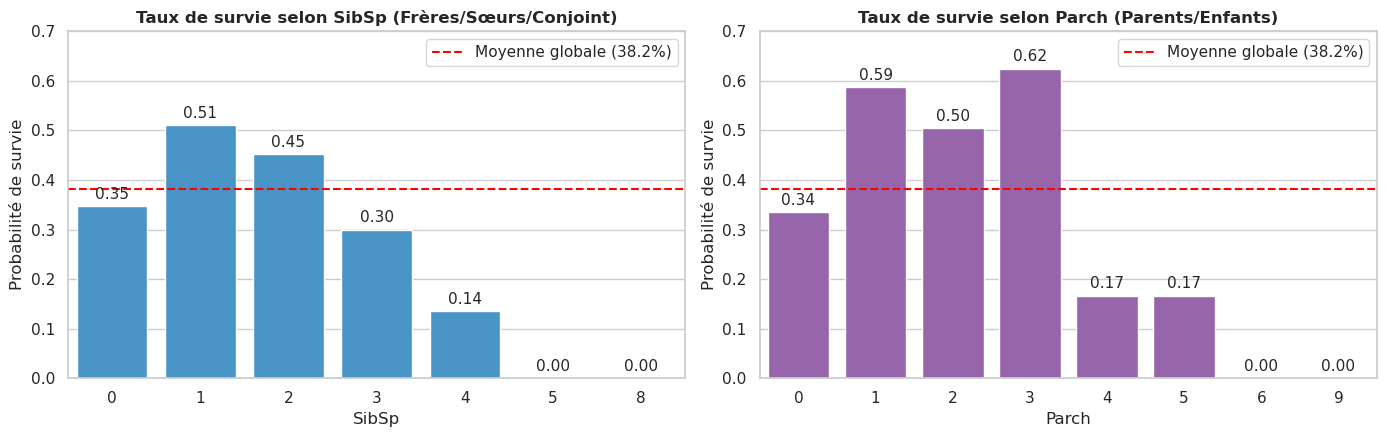

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Taux de survie selon SibSp (frères/sœurs/conjoint)
sns.barplot(data=df, x="SibSp", y="Survived", color="#3498db", errorbar=None, ax=axes[0])
axes[0].axhline(df["Survived"].mean(), color="red", linestyle="--", label="Moyenne globale (38.2%)")
axes[0].set_title("Taux de survie selon SibSp (Frères/Sœurs/Conjoint)", fontweight="bold")
axes[0].set_ylabel("Probabilité de survie")
axes[0].set_ylim(0, 0.7)
axes[0].legend()
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=3)

# Taux de survie selon Parch (parents/enfants)
sns.barplot(data=df, x="Parch", y="Survived", color="#9b59b6", errorbar=None, ax=axes[1])
axes[1].axhline(df["Survived"].mean(), color="red", linestyle="--", label="Moyenne globale (38.2%)")
axes[1].set_title("Taux de survie selon Parch (Parents/Enfants)", fontweight="bold")
axes[1].set_ylabel("Probabilité de survie")
axes[1].set_ylim(0, 0.7)
axes[1].legend()
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


### Enseignements clés des variables numériques pour notre SVM

1. **Pourquoi imputer par la Médiane plutôt que par la Moyenne ?**
   - Regardez `Fare` : la moitié des passagers a payé moins de **14,45 £** (la **médiane**), mais quelques billets de luxe à **512,33 £** tirent la **moyenne** jusqu'à **33,30 £** !
   - En statistique, **la médiane est robuste aux valeurs extrêmes (*outliers*)**, tandis que la moyenne est facilement faussée. C'est pourquoi on utilise `SimpleImputer(strategy='median')` sur `Age`, `SibSp`, `Parch` et `Fare`.

2. **Pourquoi appliquer un logarithme `np.log1p` sur `Fare` avant le `StandardScaler` ?**
   - Le coefficient d'asymétrie (*Skewness*) de `Fare` brut est de **4,37** (distribution extrêmement écrasée à gauche avec une longue traîne à droite).
   - Comme certains billets ont un prix de `0.00 £` (membres d'équipage ou invités de la White Star Line), on ne peut pas calculer $\ln(0)$ (qui vaut $-\infty$). On utilise donc **`np.log1p(x)`** qui calcule $\ln(1 + x)$ : ainsi $\ln(1 + 0) = 0$ et $\ln(1 + 512.33) \approx 6.24$.
   - Comme le montre le graphique en bas à droite, l'asymétrie tombe de **4,37 à 0,54**, et on distingue soudainement deux belles courbes (les billets bon marché où la mortalité domine, et les billets chers où la survie domine). Le SVM pourra séparer ces distributions bien plus facilement.
   
3. **L'impact de l'âge et de la famille (`Age`, `SibSp`, `Parch`)** :
   - **Enfants (`Age < 10 ans`)** : Pic net de survie (courbe verte au-dessus de la courbe rouge à gauche de l'histogramme).
   - **Taille de la famille (`SibSp` et `Parch`)** : Voyager avec 1 à 2 proches augmente les chances de survie (~50 à 55 %) par rapport aux voyageurs solitaires (~30–35 %), mais les **très grandes familles (`SibSp >= 3` ou `Parch >= 4`, souvent en 3ème classe)** ont un taux de survie très faible (< 15 %) car elles cherchaient à rester groupées dans les coursives avant de monter sur le pont.


## 8. Analyse des identifiants et colonnes textuelles : `PassengerId`, `Name`, `Ticket`, `Cabin`, `home.dest`

Que faire des colonnes qui contiennent un identifiant unique ou du texte libre ?
Calculons le **nombre de valeurs uniques (la cardinalité)** de chaque colonne :


In [15]:
cols_texte = ["PassengerId", "Name", "Ticket", "Cabin", "home.dest"]
resume_texte = pd.DataFrame({
    "Type": df[cols_texte].dtypes,
    "Valeurs non-nulles": df[cols_texte].notnull().sum(),
    "Valeurs manquantes (%)": (df[cols_texte].isnull().mean() * 100).round(1),
    "Nombre de valeurs uniques (Cardinalité)": df[cols_texte].nunique(),
    "Exemples": [df[c].dropna().iloc[:2].tolist() for c in cols_texte]
})
display(resume_texte)


,Type,Valeurs non-nulles,Valeurs manquantes (%),Nombre de valeurs uniques (Cardinalité),Exemples
PassengerId,int64,1309,0.0,1309,"[1, 2]"
Name,object,1309,0.0,1307,"[Braund, Mr. Owen Harris, Cumings, Mrs. John B..."
Ticket,object,1309,0.0,929,"[A/5 21171, PC 17599]"
Cabin,object,295,77.5,186,"[C85, C123]"
home.dest,object,745,43.1,369,"[Bridgerule, Devon, New York, NY]"


### Pourquoi écarter ces 5 colonnes dans le nettoyage de base pour le SVM ?

1. **`PassengerId` (1 309 valeurs uniques sur 1 309 lignes)** :
   - C'est un simple numéro de ligne (`1, 2, 3, ..., 1309`). Si on le laissait dans le modèle, le SVM apprendrait par hasard que le passager n°42 a survécu mais pas le n°43. **À supprimer systématiquement.**

2. **`Name` (1 307 valeurs uniques) et `Ticket` (929 valeurs uniques)** :
   - Ce sont des variables textuelles à **très haute cardinalité** (presque une valeur différente par passager).
   - Si on appliquait un `OneHotEncoder` dessus, on créerait plus de **2 200 nouvelles colonnes** remplies de zéros avec un seul `1` ! En géométrie des SVM, cela provoque le **fléau de la dimension (*Curse of Dimensionality*)** et un surapprentissage (*overfitting*) total.
   - *(Note : Dans un second temps dit de "Feature Engineering avancé", on peut extraire la civilité `Mr.`, `Mrs.`, `Miss.` depuis `Name`, mais la colonne brute `Name` et la colonne `Ticket` ne doivent jamais être passées telles quelles au SVM).*
   
3. **`Cabin` (77,5 % manquant, 186 valeurs uniques) et `home.dest` (43,1 % manquant, 369 valeurs uniques)** :
   - Trop de valeurs manquantes combinées à des centaines de textes différents (`"New York, NY"`, `"Bridgerule, Devon"`, `"C85"`). On les écarte donc du jeu de variables explicatives.


## 9. Analyse multivariée et Matrice de corrélation

Jusqu'ici, nous avons observé les variables une par une (*analyse univariée*) ou face à `Survived` (*analyse bivariée*).
Mais en réalité, **les variables interagissent entre elles** ! Par exemple :
- Une femme en 1ère classe avait-elle les mêmes chances de survie qu'une femme en 3ème classe ?
- Quelles variables numériques sont liées entre elles ?


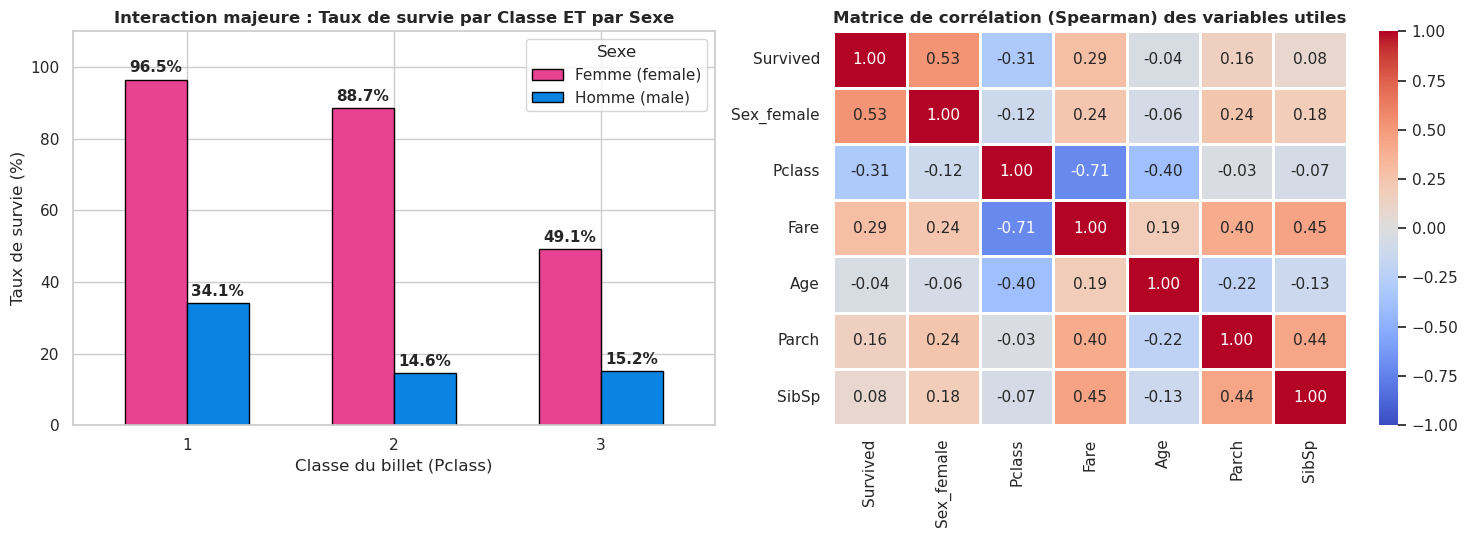

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1- Interaction Sexe x Classe sociale x Survie
surv_sex_pclass = df.groupby(["Pclass", "Sex"])["Survived"].mean().unstack() * 100
surv_sex_pclass.plot(kind="bar", color=["#e84393", "#0984e3"], ax=axes[0], rot=0, width=0.6, edgecolor="black")
axes[0].set_title("Interaction majeure : Taux de survie par Classe ET par Sexe", fontweight="bold")
axes[0].set_xlabel("Classe du billet (Pclass)")
axes[0].set_ylabel("Taux de survie (%)")
axes[0].set_ylim(0, 110)
axes[0].legend(title="Sexe", labels=["Femme (female)", "Homme (male)"])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold")

# 2- Matrice de corrélation de Spearman sur les variables clés (copie locale temporaire pour inclure Sex en binaire)
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
corr_df["Sex_female"] = (df["Sex"] == "female").astype(int)
# Réorganisation de l'ordre des colonnes
corr_df = corr_df[["Survived", "Sex_female", "Pclass", "Fare", "Age", "Parch", "SibSp"]]

sns.heatmap(
    corr_df.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=1,
    ax=axes[1]
)
axes[1].set_title("Matrice de corrélation (Spearman) des variables utiles", fontweight="bold")

plt.tight_layout()
plt.show()


### Ce que révèle l'analyse multivariée :

1. **L'interaction `Pclass` × `Sex` est spectaculaire** :
   - En **1ère classe**, **96,5 % des femmes** (139 sur 144) ont survécu !
   - En **2ème classe**, **88,7 % des femmes** ont survécu.
   - En **3ème classe**, le taux de survie des femmes chute à **49,1 %** (contre ~15 % pour les hommes de 2ème et 3ème classe, et 34,1 % pour les hommes de 1ère classe).
   - **Intérêt d'un SVM à noyau (ex: noyau RBF)** : Un SVM capable de capturer des interactions non-linéaires entre `Sex`, `Pclass`, `Age` et `Fare` exploitera directement cette différence entre une femme de 1ère/2ème classe et une femme de 3ème classe.
   
2. **Lecture de la matrice de corrélation** :
   - Avec `Survived` : les corrélations les plus fortes sont **`Sex_female` (+0.53)**, **`Fare` (+0.29)** et **`Pclass` (-0.31)** (corrélation négative car `Pclass = 1` est la classe la plus riche et `Pclass = 3` la moins chère).
   - Entre variables explicatives : `Pclass` et `Fare` sont fortement corrélés (**-0.71**, plus le numéro de classe est petit, plus le billet est cher), et `Pclass` est corrélé à `Age` (**-0.39**, les passagers de 1ère classe sont plus âgés en moyenne que ceux de 3ème classe).


<br>

## 10. Bilan de l'EDA : Feuille de route du Prétraitement pour le SVM

Notre exploration est terminée **sans avoir altéré ni découpé les données**. Chaque décision que nous allons programmer lors de l'étape suivante (le prétraitement avec `scikit-learn`) découle directement des observations de cette EDA :

| Étape | Variable(s) | Diagnostic issu de l'EDA | Décision pour le Prétraitement SVM | Outil `scikit-learn` ou `pandas` |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **`boat`, `body`** | **Fuite de données (*Data Leakage*)** enregistrée après le naufrage. | **Suppression obligatoire** avant toute chose. | `df.drop(columns=...)` |
| **1** | **`PassengerId`, `Name`, `Ticket`, `Cabin`, `home.dest`** | Identifiant sans valeur prédictive, textes à très haute cardinalité ou trop de `NaN` (77,5 % sur `Cabin`). | **Suppression** du jeu de variables explicatives $X$. | `df.drop(columns=...)` |
| **2** | **`Survived` ($y$) & Variables ($X$)** | 1 309 passagers au total (61,8 % décédés / 38,2 % survivants). | **Découpage en 2 ensembles (`Train` / `Test`)** stratifié sur $y$ juste avant le pipeline. | `train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)` |
| **3** | **`Age`, `SibSp`, `Parch`** | Numériques (`Age` a 20,1 % de `NaN`), échelles différentes (0–80 vs 0–9). | 1. Imputation par la **médiane** (`median`)<br>2. **Standardisation** (moyenne 0, écart-type 1) pour les distances du SVM. | `SimpleImputer('median')` + `StandardScaler()` |
| **3** | **`Fare`** | Numérique avec 1 `NaN`, **très forte asymétrie (*Skewness* = 4,37)** et valeurs à `0.0`. | 1. Imputation par la **médiane**<br>2. Transformation **`np.log1p`** ($\ln(1+x)$) pour corriger l'asymétrie<br>3. **Standardisation**. | `SimpleImputer('median')` + `FunctionTransformer(np.log1p)` + `StandardScaler()` |
| **3** | **`Sex`** | Catégorielle binaire (`male` / `female`), variable la plus prédictive. | 1. Imputation par la modalité la plus fréquente<br>2. **Encodage binaire** (`male` $\to 0$, `female` $\to 1$). | `SimpleImputer('most_frequent')` + `OrdinalEncoder()` |
| **3** | **`Pclass`, `Embarked`** | Catégorielles à 3 modalités (`Embarked` a 2 `NaN`). | 1. Imputation par la modalité la plus fréquente (`'S'`)<br>2. **Encodage One-Hot** avec suppression de la 1ère modalité (`drop='first'`). | `SimpleImputer('most_frequent')` + `OneHotEncoder(drop='first')` |

---
> **Règle d'or lors de l'étape suivante (Prétraitement) :**
> On effectue d'abord le `train_test_split(X, y)` pour séparer `X_train` et `X_test`, puis on calcule les paramètres du pipeline (médianes, moyennes, écarts-types) **uniquement sur `X_train`** avec `.fit_transform(X_train)`, avant de les appliquer à `X_test` avec `.transform(X_test)`.
